# E-Commerce Returns Analysis

Exploring our SQLite database to analyze product returns across categories, calculate refund totals, and estimate potential cost savings from improving sizing guides.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect('ecommerce_data_warehouse.db')

## 1. Category Return Rates (SQL)

Using a SQL query with CTEs to calculate return rates across all four product categories:

In [2]:
query = '''
WITH category_purchases AS (
    SELECT product_category, COUNT(*) AS total_purchases
    FROM transactions
    WHERE event_type = 'purchase'
    GROUP BY product_category
),
category_returns AS (
    SELECT product_category, COUNT(*) AS total_returns
    FROM transactions
    WHERE event_type = 'return'
    GROUP BY product_category
)
SELECT 
    p.product_category,
    p.total_purchases,
    COALESCE(r.total_returns, 0) AS total_returns,
    ROUND(CAST(COALESCE(r.total_returns, 0) AS FLOAT) / p.total_purchases * 100, 2) AS return_rate_pct
FROM category_purchases p
LEFT JOIN category_returns r ON p.product_category = r.product_category
ORDER BY return_rate_pct DESC;
'''

df_rates = pd.read_sql_query(query, conn)
df_rates

,product_category,total_purchases,total_returns,return_rate_pct
0,Apparel,1898,601,31.66
1,Electronics,2053,105,5.11
2,Home,1989,100,5.03
3,Beauty,2060,99,4.81


## 2. Category Return Rate Comparison

Plotting category return rates to compare against the ~5% baseline:

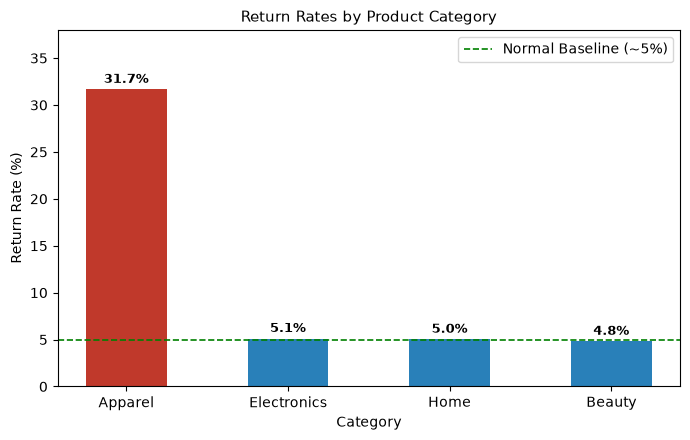

In [3]:
plt.figure(figsize=(7, 4.5))

colors = ['#c0392b' if cat == 'Apparel' else '#2980b9' for cat in df_rates['product_category']]
bars = plt.bar(df_rates['product_category'], df_rates['return_rate_pct'], color=colors, width=0.5)

plt.axhline(y=5.0, color='green', linestyle='--', linewidth=1.2, label='Normal Baseline (~5%)')

plt.title('Return Rates by Product Category', fontsize=11)
plt.ylabel('Return Rate (%)', fontsize=10)
plt.xlabel('Category', fontsize=10)
plt.ylim(0, 38)
plt.legend()

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.7, f'{height:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Total Refunds by Category

Checking how total refund amounts are distributed across categories:

In [4]:
refund_query = '''
SELECT 
    product_category,
    COUNT(*) AS total_returns,
    ROUND(SUM(refund_amount), 2) AS total_refund_inr,
    ROUND(SUM(refund_amount) * 100.0 / (SELECT SUM(refund_amount) FROM transactions WHERE event_type = 'return'), 2) AS pct_of_refunds
FROM transactions
WHERE event_type = 'return'
GROUP BY product_category
ORDER BY total_refund_inr DESC;
'''

df_refunds = pd.read_sql_query(refund_query, conn)
df_refunds

,product_category,total_returns,total_refund_inr,pct_of_refunds
0,Apparel,601,1663322.39,66.68
1,Home,100,284873.42,11.42
2,Electronics,105,283650.42,11.37
3,Beauty,99,262517.53,10.52


## 4. Cost Savings Analysis

Estimating potential cost savings if we reduce Apparel return rates by improving size guides:

In [5]:
from cost_analysis import calculate_savings

savings_df = calculate_savings()
savings_df

,Target,Projected Returns,Total Loss (Rs),Savings (Lakhs)
0,20% Return Rate,379,1124717.11,6.59
1,10% Return Rate,189,560874.76,12.23
2,5% Return Rate (Baseline),94,278953.59,15.05


In [6]:
conn.close()